In [ ]:
# 1. 라이브러리 불러오기
%matplotlib widget
# 주피터 노트북에서 matplotlib 그래프를 마우스로 조작할 수 있게 하는 설정(widget : 확대, 이동, 클릭 이벤트 등)
# 정적인 이미지를 실시간으로 조작할 수 있는 인터랙티브(Interactive) 창으로 바꿔줌

import cv2
import json
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.backend_bases import MouseEvent # 마우스 이벤트를 감지하는 클래스

In [ ]:
# 2. 빈 주차장 기준 이미지 불러오기

# 현재 Notebook 실행 위치 확인
print("현재 경로:", Path.cwd())
# D:\finalProjectB\back\ai\notebooks

# AI 프로젝트 루트 경로 설정
BASE_DIR = Path.cwd().parent
# D:\finalProjectB\back\ai

# 주차장 이미지 경로
IMAGE_PATH = BASE_DIR / "data" / "parking_spaces" / "empty_reference.jpg"

# 이미지 불러오기
image = cv2.imread(str(IMAGE_PATH))

if image is None:
    print("이미지를 찾지 못했습니다.")
    print(IMAGE_PATH)
else:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    print(f"이미지 크기: (높이, 너비, 색상 채널 수){image.shape}")

현재 경로: d:\finalProjectB\back\ai\notebooks
이미지 크기: (높이, 너비, 색상 채널 수)(480, 640, 3)


c:\Users\ICT-008\anaconda3\Lib\site-packages\ipympl\backend_nbagg.py:335: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  self.figure.savefig(buf, format='png', dpi='figure')
c:\Users\ICT-008\anaconda3\Lib\site-packages\ipympl\backend_nbagg.py:335: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  self.figure.savefig(buf, format='png', dpi='figure')
c:\Users\ICT-008\anaconda3\Lib\site-packages\ipympl\backend_nbagg.py:335: UserWarning: Glyph 47732 (\N{HANGUL SYLLABLE MYEON}) missing from font(s) DejaVu Sans.
  self.figure.savefig(buf, format='png', dpi='figure')
c:\Users\ICT-008\anaconda3\Lib\site-packages\ipympl\backend_nbagg.py:335: UserWarning: Glyph 51340 (\N{HANGUL SYLLABLE JWA}) missing from font(s) DejaVu Sans.
  self.figure.savefig(buf, format='png', dpi='figure')
c:\Users\ICT-008\anaconda3\Lib\site-packages\ipympl\backend_nbagg.py:335: UserWarning: Glyph 54364 (\N{HANGUL SYLLABLE PYO}) missing from font(s

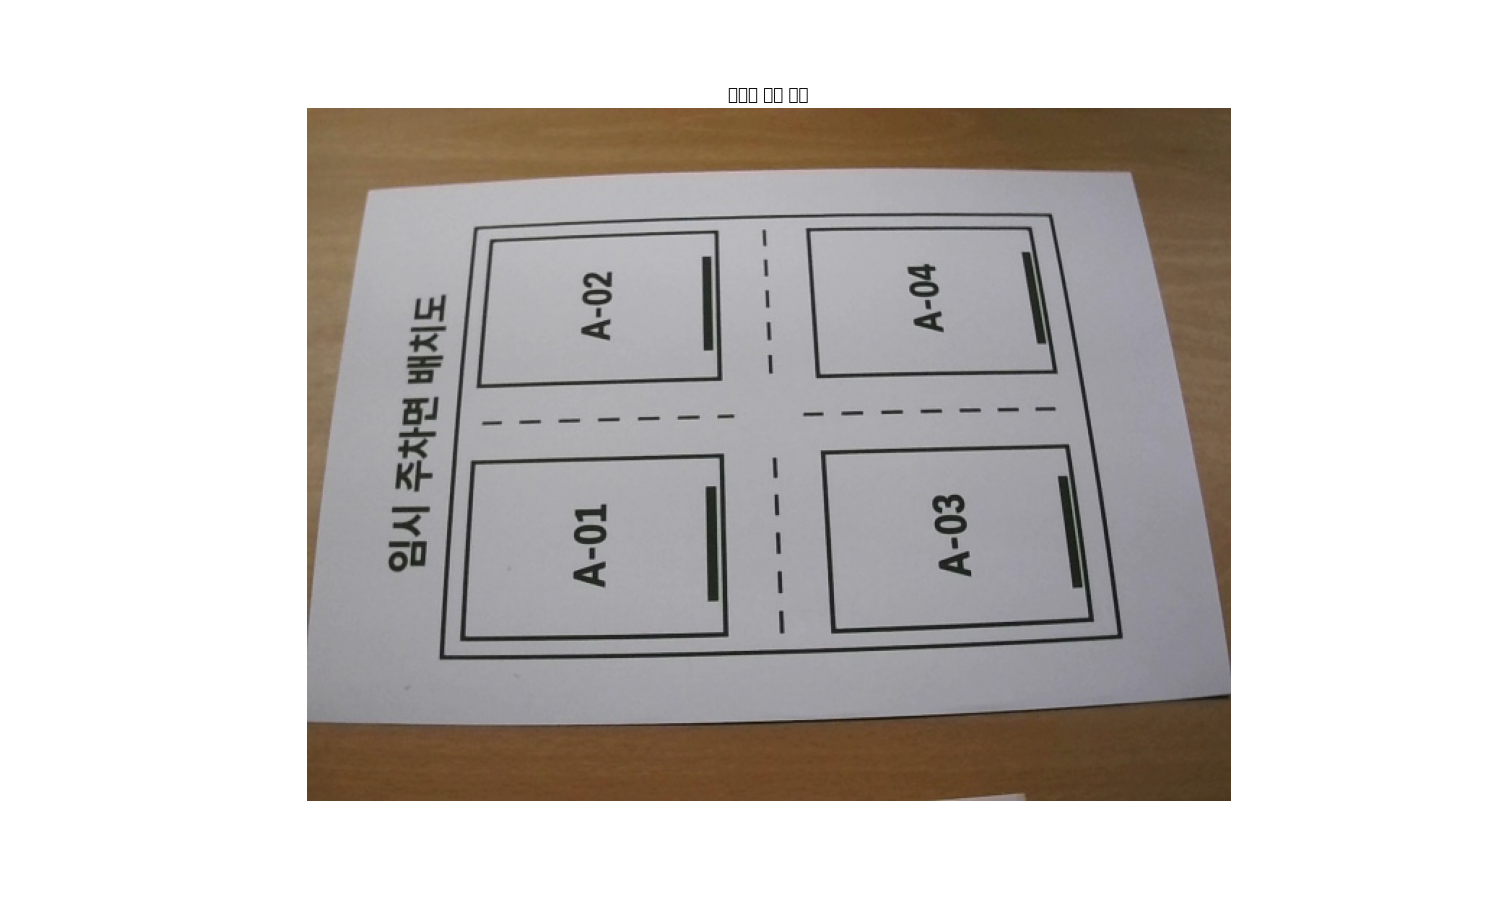

In [ ]:
# 3. Matplotlib으로 이미지 표시해보기

fig, ax = plt.subplots(figsize=(15, 9))

ax.imshow(image)
ax.set_title("주차면 좌표 지정")
ax.axis("off")

plt.show()

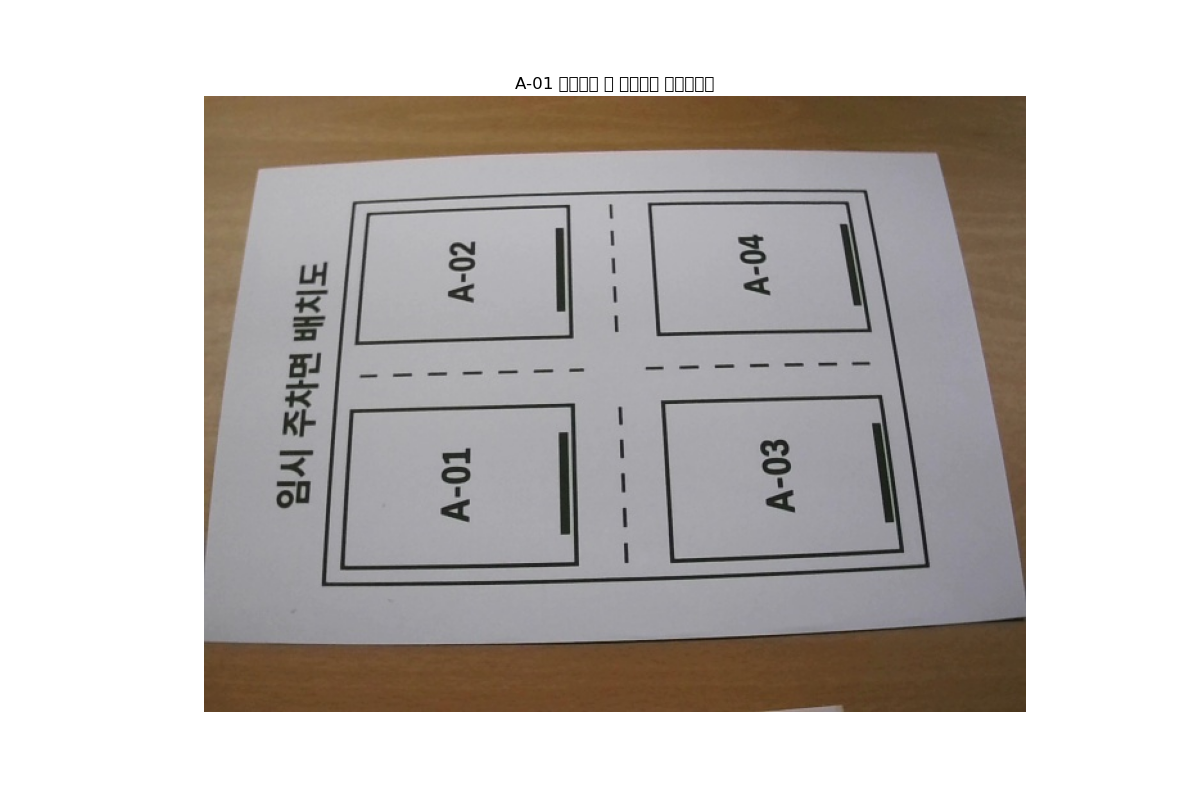

In [ ]:
# 4. 마우스 클릭으로 주차면 좌표 지정

fig, ax = plt.subplots(figsize=(12, 8))

ax.imshow(image)
ax.set_title("A-01 주차면의 네 모서리를 클릭하세요")
ax.axis("off")

# 주차면 정보를 저장할 리스트
spaces = []
# 아래처럼 데이터가 들어감
# spaces = [
#     {
#         "id": "A-01",
#         "points": [
#             [114, 246],
#             [106, 366],
#             [289, 363],
#             [285, 241]
#         ]
#     }
# ]

# 마우스 클릭 좌표를 저장할 리스트(현재 선택 중인 좌표)
# A-01 클릭하는 동안 좌표들이 추가 -> A-01이 완료되면 points가 초기화 -> A-02를 클릭할 때 다시 좌표들이 추가
points = []

# 주차면 이름
space_names = ["A-01", "A-02", "A-03", "A-04"]

#################################### 4-1. 마우스 클릭 함수 ##################################
def onclick(event: MouseEvent): # event : 마우스 클릭 이벤트 정보(x, y 좌표, 클릭한 버튼 등)
    if event.inaxes != ax or event.button != 1: # 클릭한 위치가 이미지 영역이 아닌 경우 or 마우스 왼쪽 버튼이 아닌 경우
        return # 아무 작업도 하지 않고 종료

    if len(spaces) >= 4: # 이미 4개의 주차면이 지정된 경우
        return # 더 이상 좌표를 추가하지 않음
    
    # 클릭한 위치가 이미지 영역 밖이면 좌표를 가져올 수 없으므로(None이므로) 종료
    if event.xdata is None or event.ydata is None: # event.xdata, event.ydata : 클릭한 위치의 이미지 좌표
        return 
    
    # 마우스로 클릭한 이미지상의 X, Y 좌표를 가져와 정수로 변환하여 points 리스트에 추가
    x = int(event.xdata)
    y = int(event.ydata)

    points.append([x, y]) # points 리스트에 클릭한 좌표를 추가

    # 클릭한 위치를 빨간색 점으로 표시(ro : 빨간색 원, markersize=5 : 점 크기)
    ax.plot(x, y, "ro", markersize=5)

    ######################## 4-1-1. 4개의 좌표가 모두 지정되면(클릭되면) 주차면 저장 ########################
    if len(points) == 4: # 현재 주차면의 좌표 네 개가 모였다면
        name = space_names[len(spaces)] 
        # 현재 몇 개의 주차면을 저장했는지에 따라 space_names에서 다음 주차면 이름을 가져옴
        # (주차면 이름들 : A-01, A-02, A-03, A-04)

        # 주차면 저장
        spaces.append({
            "id": name,
            "points": points.copy() # points 리스트의 내용을 별도의 리스트에 복사해서 저장
        })

        # 네 점을 선으로 연결 (점 찍을때 시계방향 혹은 반시계방향 순서대로 찍어야 함)
        polygon = points + [points[0]]
        # 아래처럼 저장됨
        # polygon = [
        #     [114, 246],
        #     [106, 366],
        #     [289, 363],
        #     [285, 241],
        #     [114, 246]
        # ]

        # 리스트 컴프리헨션으로 좌표 리스트에서 X값과 Y값을 각각 따로 추출
        xs = [p[0] for p in polygon] # 저장 예시 : xs = [114, 106, 289, 285, 114]
        ys = [p[1] for p in polygon] # 저장 예시 : ys = [246, 366, 363, 241, 246]

        ax.plot(xs, ys, color="lime", linewidth=2) # 네 모서리를 초록색 선으로 연결(linewidth=2 : 선 두께)

        print(f"{name} 좌표 지정 완료: {points}")

        ############################# 4-1-2. 다음 주차면 좌표 받을 준비 #############################
        points.clear() # 현재 주차면의 좌표를 모두 저장했으므로 points 리스트를 초기화

        # 다음 주차면 안내 및 화면 갱신
        if len(spaces) < 4: # 아직 4개의 주차면이 모두 지정되지 않은 경우
            ax.set_title( # set_title : 그래프 상단에 제목 표시
                f"{space_names[len(spaces)]} 주차면의 네 모서리를 클릭하세요"
            )
        else: # 4개의 주차면이 모두 지정된 경우
            ax.set_title("주차면 4개 지정 완료")
        
    fig.canvas.draw_idle() # 마우스로 좌표를 찍었을 때 화면에 새로 그린 점과 선이 나타나도록 화면 갱신을 요청
    
########################################## 4-2. 마우스 클릭 이벤트 연결 ##########################################
cid = fig.canvas.mpl_connect("button_press_event", onclick)
# mpl_connect : 마우스 클릭 이벤트를 연결하는 함수
# "button_press_event" : 마우스를 클릭했을 때 발생하는 이벤트
# onclick : 마우스 클릭 이벤트가 발생했을 때 호출될 함수 (위에 만든거)
# cid : 등록한 이벤트 연결 번호, 나중에 이벤트를 해제할 때 사용
# fig.canvas.mpl_disconnect(cid) 로 해제

plt.show()

In [ ]:
# 5. 4개 좌표를 하나의 주차면으로 저장
for space in spaces:
    print(space["id"], ":", space["points"])
# print(points)

A-01 : [[114, 246], [106, 366], [289, 363], [285, 241]]
A-02 : [[127, 92], [118, 191], [285, 187], [282, 85]]
A-03 : [[356, 238], [363, 361], [542, 354], [526, 235]]
A-04 : [[346, 83], [353, 184], [517, 181], [500, 82]]


In [ ]:
# 6. JSON으로 저장

SAVE_PATH = BASE_DIR / "data" / "parking_spaces" / "parking_spots.json"

# JSON 파일 저장할 경로
SAVE_PATH.parent.mkdir(parents=True, exist_ok=True)
# 저장할 폴더가 없다면 자동으로 생성(parents=True : 상위 폴더도 필요하면 함께 생성)
# exist_ok=True : 이미 폴더가 있어도 에러 발생 x

data = { # 최종 JSON에 들어갈 정보 구성
    "image_width": image.shape[1],
    "image_height": image.shape[0],
    "spaces": spaces
}

with open(SAVE_PATH, "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=4)
    # 데이터를 JSON 파일로 저장
    # ensure_ascii=False : 한글 안깨지게
    # indent=4 : 들여쓰기 4

print("주차면 좌표 저장 완료!")
print(SAVE_PATH)

주차면 좌표 저장 완료!
d:\finalProjectB\back\ai\data\parking_spaces\parking_spots.json
